# Multiple Dataset

In [1]:
order = [
    #Popular Representation
    'pipe_serialized',
    'token_serialized',
    'space_serialized',
    "centroid_popular",
    # Data Representation
    'csv',
    'tsv',
    'html',
    'markdown',
    'latex',
    'dict',
    'json',
    'xml',
    "centroid_data",
    # Structural Transformations 
    'shuffled_rows',
    'shuffled_cols',
    'transpose',
    "centroid_structural",
    #Schema Definition Types
    'mschema',
    'macschema',
    'ddl',
    "centroid_schema",
     "centroid_all", 
]
category = {"Popular Representation": ['pipe_serialized',    'token_serialized', 'space_serialized',"centroid_popular"],
    "Data Representation" : [
            'csv',
            'tsv',
            'html',
            'markdown',
            'latex',
            'dict',
            'json',
            'xml',
            'centroid_data'],
    "Structural Transformations": ['shuffled_rows',
        'shuffled_cols',
        'transpose',
        'centroid_structural'],
    "Schema Definition Types" :['mschema',
    'macschema',
    'ddl',
    'centroid_schema'],
    "All" :['centroid_all'],
    "Top 5": [  "tsv_csv_space_serialized_ddl_latex","tsv_csv_pipe_serialized_space_serialized_transpose","xml_dict_json_pipe_serialized_markdown","xml_ddl_latex_html_token_serialized"],
    "Top 5 All": ["csv_tsv_pipe_serialized_space_serialized_xml_latex"],
}
category_wo_centroid = {"Popular Representation": ['pipe_serialized',    'token_serialized', 'space_serialized'],
    "Data Representation" : [
            'csv',
            'tsv',
            'html',
            'markdown',
            'latex',
            'dict',
            'json',
            'xml',
            ],
    "Structural Transformations": ['shuffled_rows',
        'shuffled_cols',
        'transpose'],
    "Schema Definition Types" :['mschema',
    'macschema',
    'ddl'],
    "Top 5": [   "tsv_csv_space_serialized_ddl_latex","tsv_csv_pipe_serialized_space_serialized_transpose","xml_dict_json_pipe_serialized_markdown","xml_ddl_latex_html_token_serialized"],
     "Top 5 All": ["csv_tsv_pipe_serialized_space_serialized_xml_latex"]
}
RESULT_DIR = "/data/Kushal/UniversalRetrieval_data/"

# Latex

In [21]:
import pandas as pd
import numpy as np
from pathlib import Path

representative_order = [
    "pipe_serialized", "token_serialized", "space_serialized",
    "csv", "tsv", "html", "markdown", "latex", "dict", "json", "xml",
    "shuffled_rows", "shuffled_cols", "transpose",
    "mschema", "macschema", "ddl", "centroid_all"
]

models = ["splade", "qwen0.6B", "qwen4B", "miniLM", "mdbr", "bge", "mpnet", "reasonir"]
adapter_types = ["base", "adapter", "adapter_subset"]
datasets = ["WTQ", "WIKISQL", "NQ"]

df_list = []

for adapter_type in adapter_types:
    for dataset in datasets:
        for model in models:
            model_train_date = "2026-09-17" if model in ["bge", "splade", "miniLM"] and adapter_type in ["adapter", "adapter_subset"] else "2026-09-12"
            df_model = None

            for representative in representative_order:
                if adapter_type == "base":
                    fpath = f"{RESULT_DIR}/retrieval_all/{model}_results_rank/{dataset}/chunked_{representative}_gold_rank_per_question.csv"
                else:
                    fpath = f"{RESULT_DIR}/retrieval_all/{model}_results_rank_with_{adapter_type}/{model_train_date}/{dataset}/chunked_{representative}_gold_rank_per_question.csv"

                if not Path(fpath).exists():
                    print(f"[skip] {fpath}")
                    continue

                df_rep = pd.read_csv(fpath)[["model", "dataset", "question_id", "rank"]].copy()
                df_rep = df_rep.rename(columns={"rank": representative})

                if df_model is None:
                    df_model = df_rep
                else:
                    df_model = df_model.merge(df_rep, on=["model", "dataset", "question_id"], how="inner", validate="one_to_one")

            if df_model is None:
                print(f"[warning] No files found for {adapter_type} | {dataset} | {model}")
                continue

            df_model["adapter_type"] = adapter_type
            df_list.append(df_model)

df = pd.concat(df_list, ignore_index=True).drop_duplicates()

# Match the model naming used in the original table
df["Model"] = np.where(
    df["adapter_type"] == "base",
    df["model"],
    df["model"] + "_" + df["adapter_type"]
)

df["Dataset"] = df["dataset"]
df["Model"] = df["Model"].str.replace("_adapter_subset", r"---~$\diamondsuit$", regex=False)
df["Model"] = df["Model"].str.replace("_adapter", r"---~$\spadesuit$", regex=False)
# Convert representation rank columns to long format
rank_long = df.melt(
    id_vars=["Dataset", "Model", "question_id", "adapter_type"],
    value_vars=representative_order,
    var_name="Representation",
    value_name="rank"
)

rank_long = rank_long.dropna(subset=["rank"])
base_models_w_adapter = [
    variant
    for model in models
    for variant in [
        model,
        model + r"---~$\spadesuit$",
        model + r"---~$\diamondsuit$"
    ]
]

In [22]:
topk = 10

rank_long[f"recall@{topk}"] = (rank_long["rank"] <= topk).astype(float)
rank_long[f"ndcg@{topk}"] = np.where(rank_long["rank"] <= topk, 1 / np.log2(rank_long["rank"] + 1), 0.0)

summary = (
    rank_long
    .groupby(["Dataset", "Model", "Representation"])
    .agg(
        recall=(f"recall@{topk}", "mean"),
        ndcg=(f"ndcg@{topk}", "mean")
    )
    .reset_index()
)

summary["recall_round"] = summary["recall"].round(2)
summary["ndcg_round"] = summary["ndcg"].round(2)

summary["max_recall"] = summary.groupby(["Dataset", "Model"])["recall_round"].transform("max")
summary["max_ndcg"] = summary.groupby(["Dataset", "Model"])["ndcg_round"].transform("max")

def format_value(row):
    recall_str = f"{row['recall_round']:.2f}"
    ndcg_str = f"{row['ndcg_round']:.2f}"

    if row["recall_round"] == row["max_recall"]:
        recall_str = rf"\textbf{{{recall_str}}}"

    if row["ndcg_round"] == row["max_ndcg"]:
        ndcg_str = rf"\textbf{{{ndcg_str}}}"

    return f"{recall_str} ({ndcg_str})"

summary["value"] = summary.apply(format_value, axis=1)


base_models_w_adapter = [
    variant
    for model in models
    for variant in [
        model,
        model + r"---~$\spadesuit$",
        model + r"---~$\diamondsuit$"
    ]
]

for dataset in datasets:
    table = (
        summary[summary["Dataset"] == dataset]
        .pivot(index="Model", columns="Representation", values="value")
        .reindex(columns=representative_order)
        .reindex(index=base_models_w_adapter)
    )

    print(
        table.to_latex(
            escape=False,
            na_rep="",
            caption=f"{dataset} retrieval results. Each entry reports Recall@10 (NDCG@10).",
            label=f"tab:{dataset.lower()}_recall_ndcg_10",
            column_format="l" + "c" * len(table.columns)
        )
    )

\begin{table}
\caption{WTQ retrieval results. Each entry reports Recall@10 (NDCG@10).}
\label{tab:wtq_recall_ndcg_10}
\begin{tabular}{lcccccccccccccccccc}
\toprule
Representation & pipe_serialized & token_serialized & space_serialized & csv & tsv & html & markdown & latex & dict & json & xml & shuffled_rows & shuffled_cols & transpose & mschema & macschema & ddl & centroid_all \\
Model &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  \\
\midrule
splade & \textbf{0.68} (\textbf{0.54}) & 0.64 (0.50) & 0.67 (\textbf{0.54}) & \textbf{0.68} (\textbf{0.54}) & 0.67 (\textbf{0.54}) & 0.62 (0.48) & 0.65 (0.51) & 0.67 (0.53) & 0.67 (0.53) & 0.66 (0.52) & 0.66 (0.52) & \textbf{0.68} (\textbf{0.54}) & 0.67 (0.53) & \textbf{0.68} (\textbf{0.54}) & 0.67 (0.53) & 0.66 (0.52) & 0.66 (0.52) & \textbf{0.68} (\textbf{0.54}) \\
splade---~$\spadesuit$ & \textbf{0.68} (\textbf{0.54}) & 0.65 (0.51) & 0.67 (\textbf{0.54}) & \textbf{0.68} (\textbf{0.54}) & 0.67 (\textbf{0.54}) & 0.65 (0.51) & 0.66 (0.52) 

# Compare Standard Deviation

In [23]:
df_wo_centroid = rank_long[~rank_long["Representation"].str.contains("centroid", na=False)].copy()

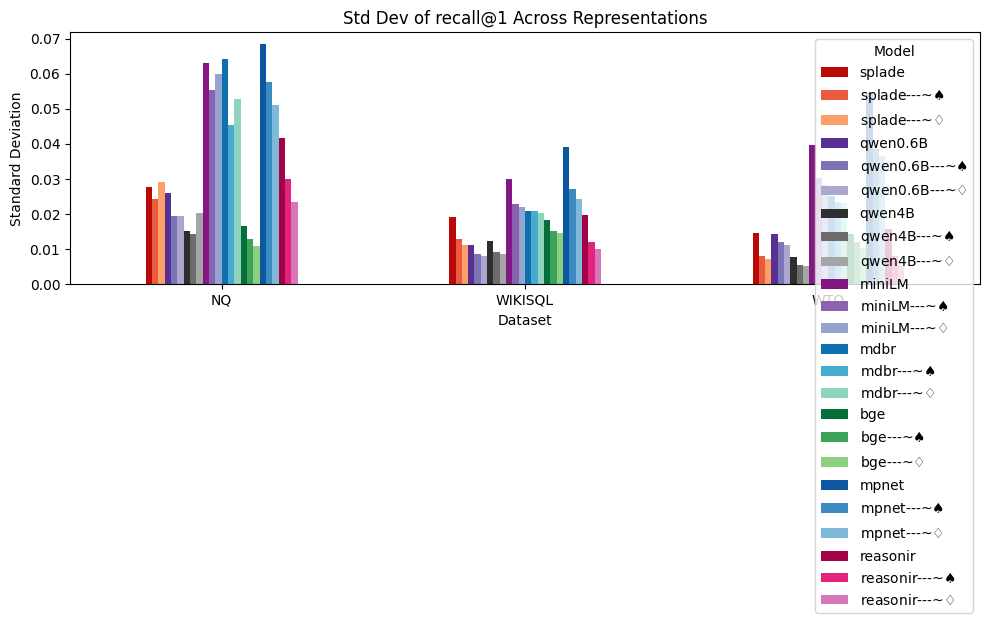

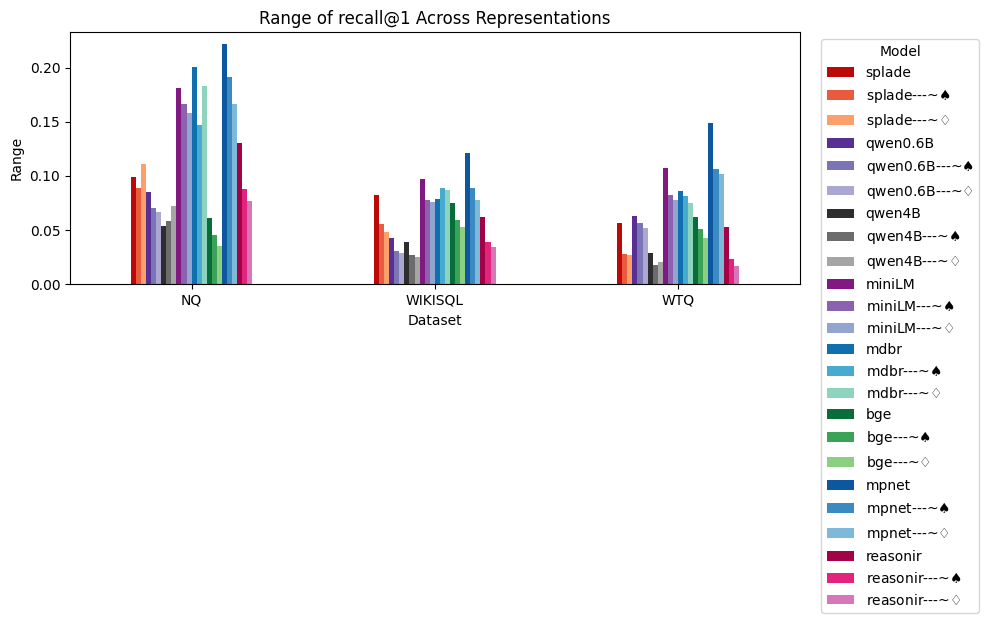

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

metric = "recall@1"

# Create retrieval metric from rank
df_wo_centroid[metric] = (df_wo_centroid["rank"] <= 1).astype(float)

base_models = ["splade", "qwen0.6B", "qwen4B", "miniLM", "mdbr", "bge", "mpnet", "reasonir"]

variants = [
    "",
    r"---~$\spadesuit$",
    r"---~$\diamondsuit$"
]

cmaps = {
    "splade": plt.cm.OrRd,
    "qwen0.6B": plt.cm.Purples,
    "qwen4B": plt.cm.Greys,
    "miniLM": plt.cm.BuPu,
    "mdbr": plt.cm.GnBu,
    "bge": plt.cm.YlGn,
    "mpnet": plt.cm.Blues,
    "reasonir": plt.cm.PuRd,
}

shade_levels = [0.85, 0.65, 0.45]

hue_order = [m + v for m in base_models for v in variants]

palette = {
    m + v: cmaps[m](shade_levels[i])
    for m in base_models
    for i, v in enumerate(variants)
}

variation = (
    df_wo_centroid
    .groupby(["Dataset", "Model", "Representation"])[metric]
    .mean()
    .reset_index()
    .groupby(["Dataset", "Model"])[metric]
    .agg(std="std", min_val="min", max_val="max", mean="mean", n="count")
    .reset_index()
)

variation["range"] = variation["max_val"] - variation["min_val"]

dataset_summary = (
    variation
    .groupby("Dataset")[["std", "range"]]
    .mean()
    .reset_index()
    .rename(columns={
        "std": "avg_std_across_models",
        "range": "avg_range_across_models"
    })
)

present_models = [m for m in hue_order if m in variation["Model"].unique()]
plot_colors = [palette[m] for m in present_models]

std_pivot = (
    variation
    .pivot(index="Dataset", columns="Model", values="std")
    .reindex(columns=present_models)
)

ax = std_pivot.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    color=plot_colors
)

ax.set_title(f"Std Dev of {metric} Across Representations")
ax.set_xlabel("Dataset")
ax.set_ylabel("Standard Deviation")
plt.tight_layout()
plt.show()

range_pivot = (
    variation
    .pivot(index="Dataset", columns="Model", values="range")
    .reindex(columns=present_models)
)

ax = range_pivot.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    color=plot_colors
)

ax.set_title(f"Range of {metric} Across Representations")
ax.set_xlabel("Dataset")
ax.set_ylabel("Range")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [28]:
display_names = {
    "splade": "SPLADE",
    "qwen0.6B": "Qwen0.6B",
    "qwen4B": "Qwen4B",
    "miniLM": "MiniLM",
    "mdbr": "MDBR",
    "bge": "BGE-M3",
    "mpnet": "MPNet",
    "reasonir": "ReasonIR"
}

base_models = [
    "splade", "qwen0.6B", "qwen4B", "miniLM",
    "mdbr", "bge", "mpnet", "reasonir"
]

variants = [
    "",
    r"---~$\spadesuit$",
    r"---~$\diamondsuit$"
]

dataset_order = ["WTQ", "WIKISQL", "NQ"]

variation_lookup = variation.set_index(["Dataset", "Model"])

lines = [
    r"\begin{table*}[h]",
    r"\centering",
    r"\resizebox{\linewidth}{!}{",
    r"\begin{tabular}{l",
    r"    S[table-format=1.3] S[table-format=1.3] S[table-format=1.3] S[table-format=1.3]",
    r"    S[table-format=1.3] S[table-format=1.3] S[table-format=1.3] S[table-format=1.3]",
    r"    S[table-format=1.3] S[table-format=1.3] S[table-format=1.3] S[table-format=1.3]}",
    "",
    r"\toprule",
    r"& \multicolumn{4}{c}{\textbf{WTQ}} & \multicolumn{4}{c}{\textbf{WIKISQL}} & \multicolumn{4}{c}{\textbf{NQ-Tables}} \\",
    r"\cmidrule(lr){2-5} \cmidrule(lr){6-9} \cmidrule(lr){10-13}",
    r"{Model} & {Std} & {Min} & {Max} & {Range} & {Std} & {Min} & {Max} & {Range} & {Std} & {Min} & {Max} & {Range} \\",
    r"\midrule"
]

for model_idx, base_model in enumerate(base_models):
    for variant_idx, variant in enumerate(variants):
        full_model = base_model + variant

        if variant_idx == 0:
            model_label = rf"\texttt{{{display_names[base_model]}}}"
        elif variant_idx == 1:
            model_label = r"\quad---~$\spadesuit$"
        else:
            model_label = r"\quad---~$\diamondsuit$"

        values = []

        for dataset in dataset_order:
            key = (dataset, full_model)

            if key in variation_lookup.index:
                row = variation_lookup.loc[key]
                values.extend([
                    f"{row['Std']:.3f}",
                    f"{row['Min']:.3f}",
                    f"{row['Max']:.3f}",
                    f"{row['Range']:.3f}"
                ])
            else:
                values.extend(["{}", "{}", "{}", "{}"])

        lines.append(model_label + " & " + " & ".join(values) + r" \\")

    if model_idx < len(base_models) - 1:
        lines.append(r"\midrule")

lines.extend([
    r"\bottomrule",
    r"\end{tabular}",
    r"}",
    r"\caption{Retrieval score variation statistics (std, min, max, range) for each model across \textbf{WTQ}, \textbf{WIKISQL}, and \textbf{NQ-Tables}. $\spadesuit$ marks the joint adapter trained on all three datasets (\textbf{WTQ}, \textbf{WIKISQL}, and \textbf{NQ-Tables}), and $\diamondsuit$ marks the subset adapter trained on a subset of datasets (\textbf{WTQ} and \textbf{WIKISQL}) for each embedding model.}",
    r"\label{tab:standard_deviation}",
    r"\end{table*}"
])

latex_table = "\n".join(lines)
print(latex_table)

\begin{table*}[h]
\centering
\resizebox{\linewidth}{!}{
\begin{tabular}{l
    S[table-format=1.3] S[table-format=1.3] S[table-format=1.3] S[table-format=1.3]
    S[table-format=1.3] S[table-format=1.3] S[table-format=1.3] S[table-format=1.3]
    S[table-format=1.3] S[table-format=1.3] S[table-format=1.3] S[table-format=1.3]}

\toprule
& \multicolumn{4}{c}{\textbf{WTQ}} & \multicolumn{4}{c}{\textbf{WIKISQL}} & \multicolumn{4}{c}{\textbf{NQ-Tables}} \\
\cmidrule(lr){2-5} \cmidrule(lr){6-9} \cmidrule(lr){10-13}
{Model} & {Std} & {Min} & {Max} & {Range} & {Std} & {Min} & {Max} & {Range} & {Std} & {Min} & {Max} & {Range} \\
\midrule
\texttt{SPLADE} & 0.015 & 0.363 & 0.419 & 0.056 & 0.019 & 0.426 & 0.508 & 0.082 & 0.028 & 0.358 & 0.458 & 0.099 \\
\quad---~$\spadesuit$ & 0.008 & 0.386 & 0.414 & 0.028 & 0.013 & 0.452 & 0.507 & 0.056 & 0.024 & 0.367 & 0.457 & 0.089 \\
\quad---~$\diamondsuit$ & 0.007 & 0.378 & 0.405 & 0.027 & 0.011 & 0.452 & 0.500 & 0.049 & 0.029 & 0.254 & 0.364 & 0.111 \\
\midr

# Plot Training Trajetory

In [ ]:
from pathlib import Path
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def read_jsonl_logs(path: Path) -> pd.DataFrame:
    """Read a jsonl log file of the latest run and return a DataFrame of only type=='log' rows."""
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            obj = json.loads(line)
            if obj.get("type") == "meta":
                rows = []
                meta= obj["cfg"]
                meta["D"] = obj["D"]
            if obj.get("type") == "log":
                rows.append(obj)
    if not rows:
        return pd.DataFrame()
    df = pd.DataFrame(rows)
    df = df.sort_values("step")
    return df, meta

miniLM 384
mdbr 768
mpnet 768
bge 1024
splade 30522
qwen0.6B 1024
qwen4B 2560
reasonir 4096
miniLM 384
mdbr 768
mpnet 768
bge 1024
splade 30522
qwen0.6B 1024
qwen4B 2560
reasonir 4096


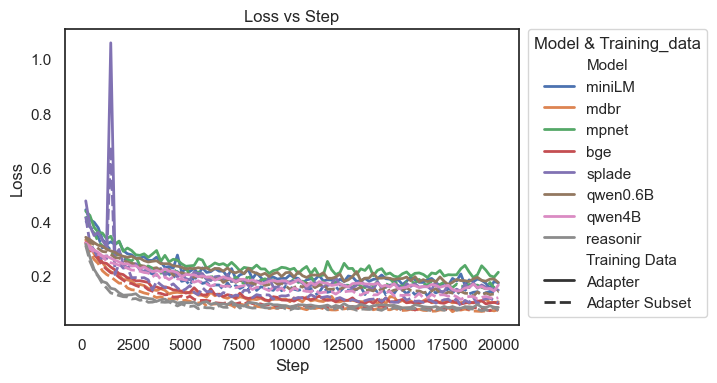

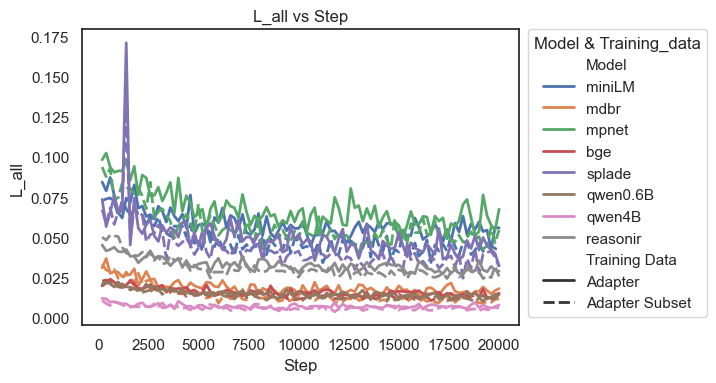

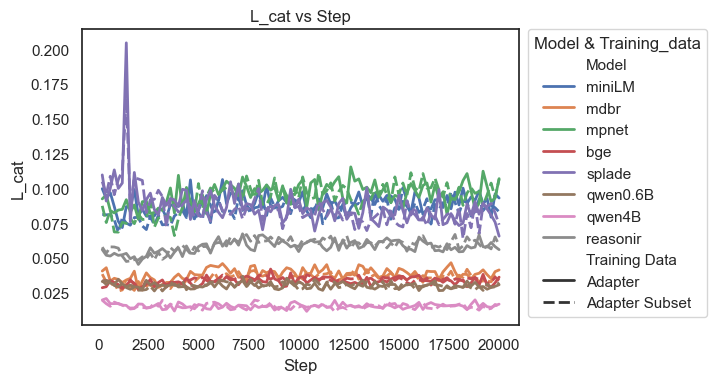

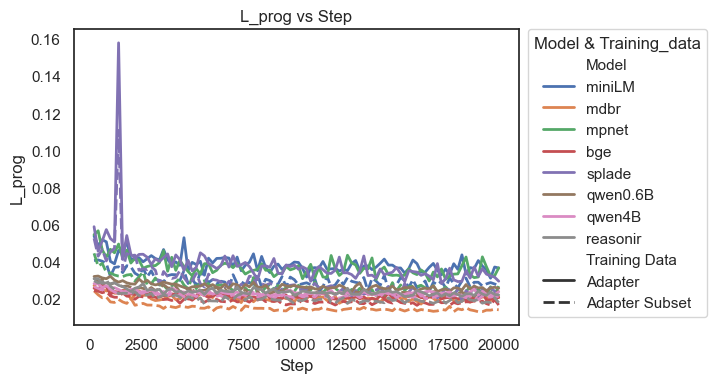

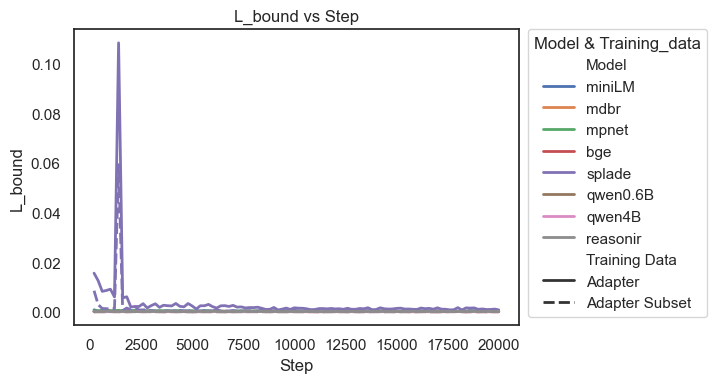

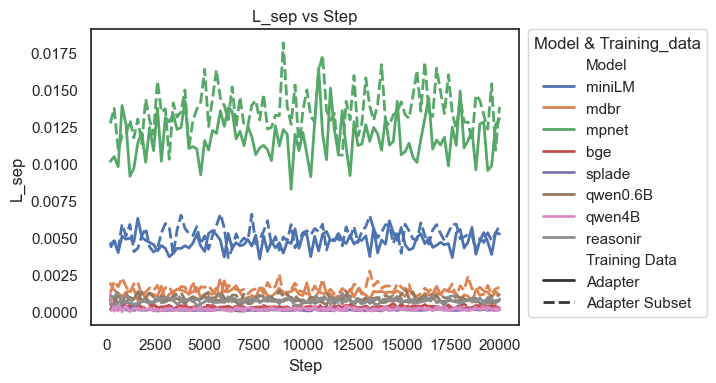

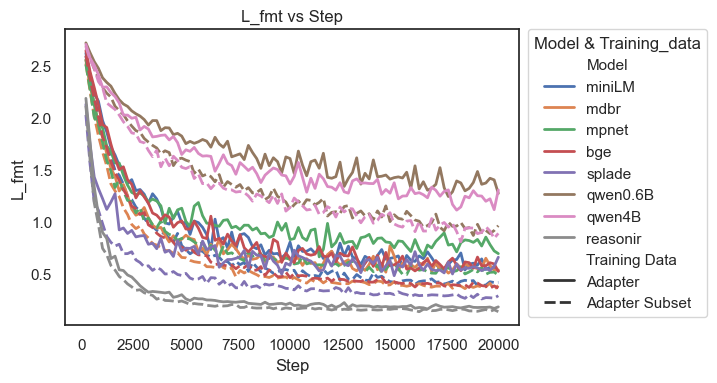

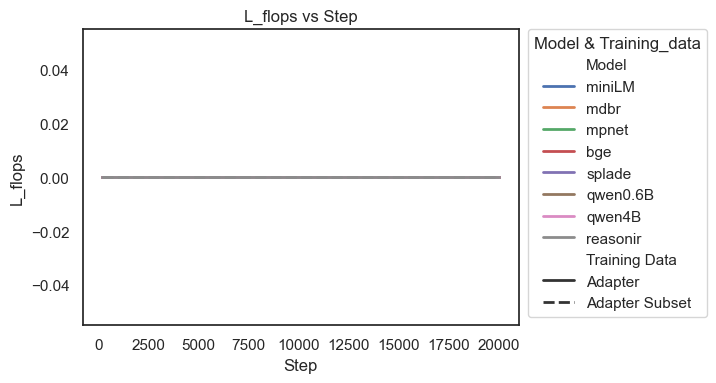

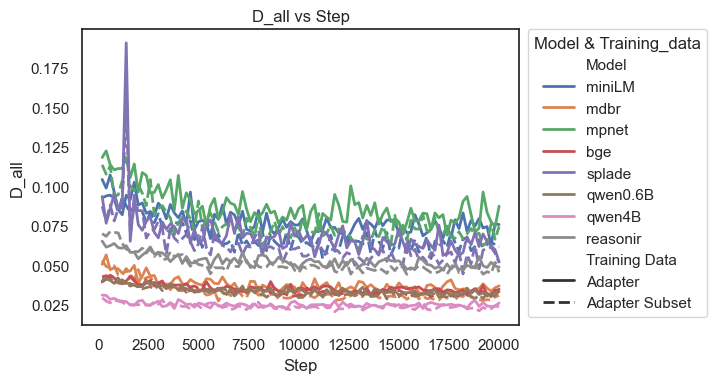

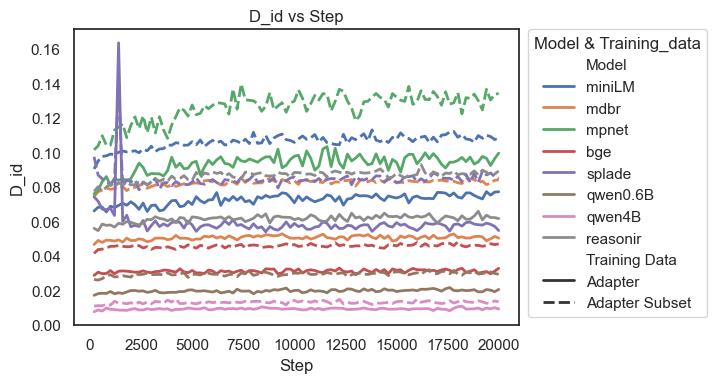

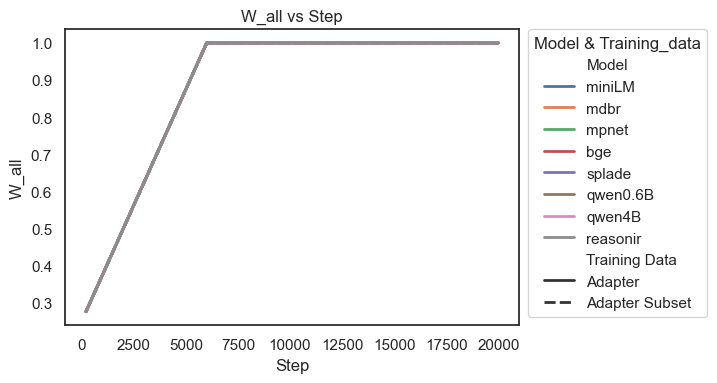

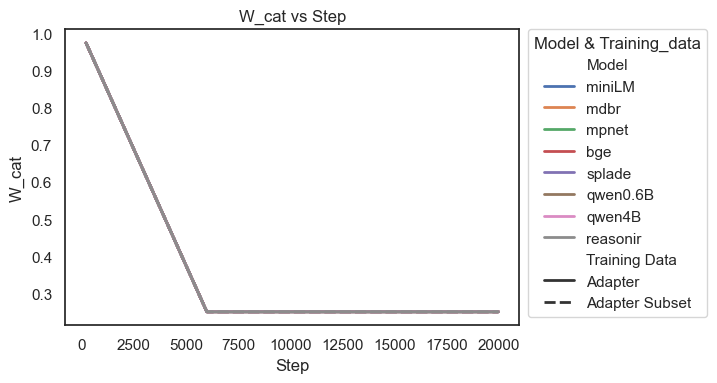

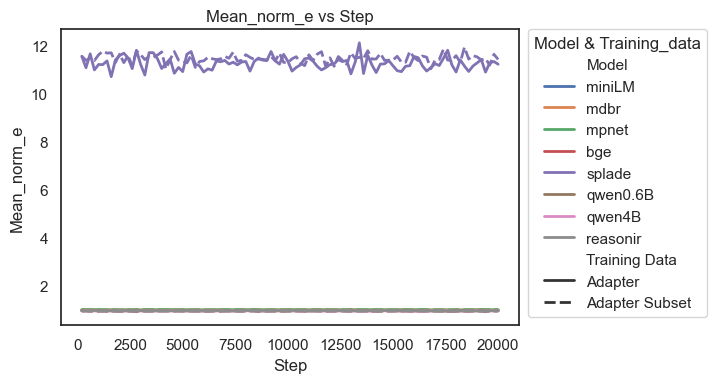

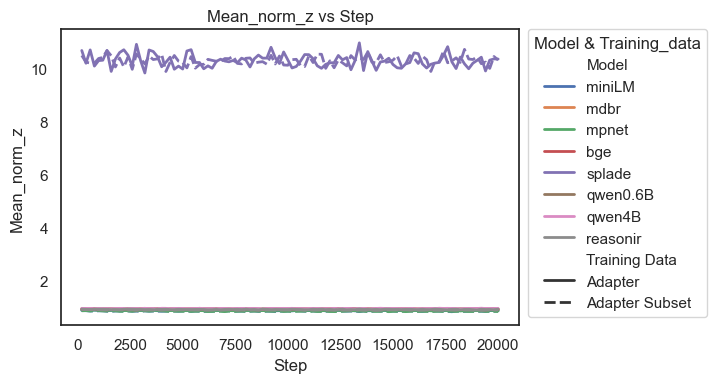

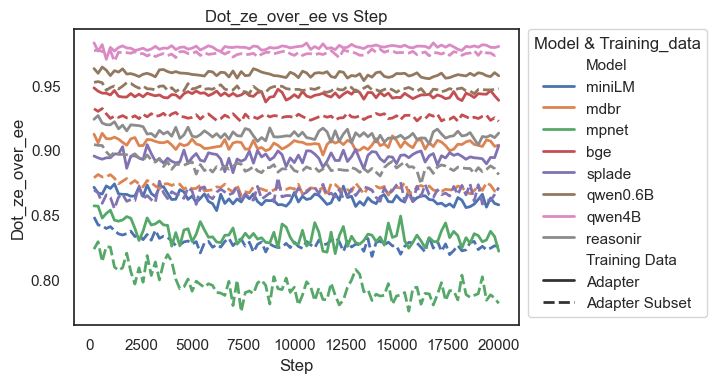

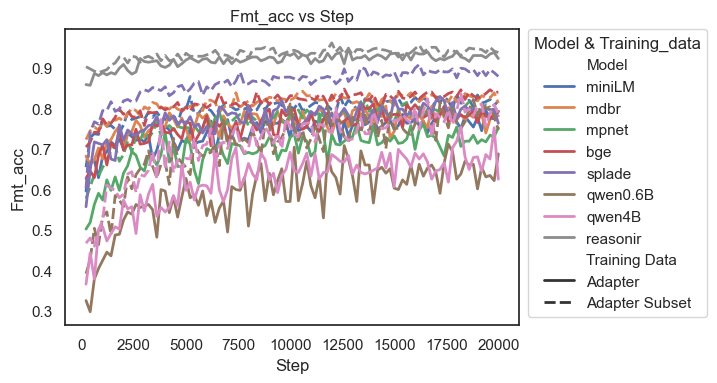

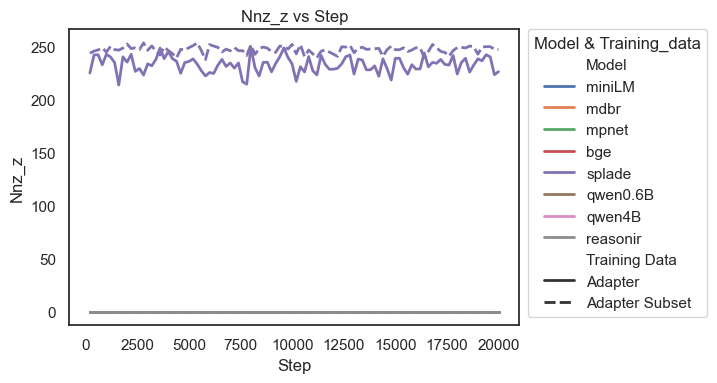

In [ ]:

# ---- point this at your folder/pattern ----
all_dfs = []
all_meta = {}
training_data = [("Adapter", "centroid_adapter"),("Adapter Subset", "centroid_adapter_subset_dataset")]#[("NQ+WIKISQL+WTQ", "centroid_adapter"),("WIKISQL+WTQ", "centroid_adapter_subset_dataset")]
#training_data = [("2026-03-10", "2026-03-10"),("2026-03-01", "2026-03-01"),("2026-02-29", "2026-02-29")]
for training, folder_name in training_data:
    for model in  ["miniLM", "mdbr", "mpnet", "bge", "splade", "qwen0.6B", "qwen4B", "reasonir"]: #,"splade"
        date = "2026-09-17" if model in ["bge","splade","miniLM"] and training in ["adapter","adapter_subset"] else "2026-09-12"
        path = f"/data/Kushal/UniversalRetrieval_data/{date}/{folder_name}/{model}/trajectory.jsonl"
        try:
            df,meta = read_jsonl_logs(path)
        except:
            continue
        df["Model"] = [model]*df.shape[0]
        df["Training Data"] = training 
        all_dfs.append(df)
        all_meta[model] = meta
        print(model, meta["D"])
df = pd.concat([d for d in all_dfs if not d.empty], ignore_index=True)

# Choose metrics you want to plot (must exist as columns)
metrics = ["loss",  'L_all', 'L_cat', 'L_prog', 'L_bound', 'L_sep','L_fmt', 'L_flops', 'd_all', 'd_id', 'w_all', 'w_cat', 'mean_norm_e','mean_norm_z', 'dot_ze_over_ee', 'fmt_acc', 'nnz_z',]

sns.set_theme(style="white")

for m in metrics:
    if m not in df.columns:
        print(f"Skipping {m}: not found in data.")
        continue

    d = df[["step", "Model", "Training Data", m]].dropna()

    plt.figure(figsize=(9, 4))
    ax = sns.lineplot(
        data=d,
        x="step",
        y=m,
        hue="Model",
        style="Training Data",   # <-- separate markets by linestyle
        estimator=None,
        lw=2
    )
    # Put legend outside the plot
    ax.legend(
        title="Model & Training_data",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0
    )
    ax.set_ylabel(m.capitalize())
    ax.set_xlabel("Step")

    # Make space for the outside legend
    plt.title(f"{m.capitalize()} vs Step")
    plt.tight_layout(rect=[0, 0, 0.82, 1])
    plt.show()
